# Top Anime Dataset — Exploratory Data Analysis

**Author:** Nguyen Doan Duy Khoa
**Dataset:** `top_anime_dataset.csv` (15,000 anime titles)


## 1. Project Overview

This project explores a catalogue of 15,000 anime titles to understand what drives audience
favoritism and average score, and how the anime industry's output has evolved over time. The
notebook profiles data quality, cleans and standardizes the `genres` field, then answers a set of
concrete questions about the most-favorited titles, score by anime type, output volume by year,
and score by genre.


## 2. Objectives / Analytical Questions

1. How complete is the dataset, and are there data-quality issues that could affect the analysis?
2. Which anime titles have the most favorites, and what does that tell us about audience taste?
3. Does the average score differ by anime `type` (TV, Movie, OVA, etc.)?
4. How has the number of anime titles released changed over time?
5. Which genres tend to have the highest average score?


## 3. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 4. Dataset Overview

In [2]:
anime = pd.read_csv('top_anime_dataset.csv')

In [3]:
# Preview the first rows
anime.head()

,anime_id,english_name,score,genres,synopsis,type,episodes,premiered,producers,studios,source,duration,Age_can_read,rank,popularity,favorites,scored_by
0,52991,Frieren: Beyond Journey's End,9.31,"Adventure, Drama, Fantasy",During their decade-long quest to defeat the D...,TV,28.0,fall 2023,"Aniplex, Dentsu, Shogakukan-Shueisha Productio...",Madhouse,Manga,24 min per ep,PG-13 - Teens 13 or older,1.0,160,63200,603520
1,5114,Fullmetal Alchemist: Brotherhood,9.10,"Action, Adventure, Drama, Fantasy",After a horrific alchemy experiment goes wrong...,TV,64.0,spring 2009,"Aniplex, Square Enix, Mainichi Broadcasting Sy...",Bones,Manga,24 min per ep,R - 17+ (violence & profanity),2.0,3,231928,2196353
2,9253,Steins;Gate,9.07,"Drama, Sci-Fi, Suspense",Eccentric scientist Rintarou Okabe has a never...,TV,24.0,spring 2011,"Frontier Works, Media Factory, Kadokawa Shoten...",White Fox,Visual novel,24 min per ep,PG-13 - Teens 13 or older,3.0,14,194507,1449844
3,60022,NaN,9.06,"Action, Adventure, Fantasy",Although the golden age of piracy is about to ...,TV Special,1.0,NaN,NaN,Toei Animation,Light novel,24 min,PG-13 - Teens 13 or older,4.0,2350,1970,68977
4,38524,Attack on Titan Season 3 Part 2,9.05,"Action, Drama, Suspense",Seeking to restore humanity's diminishing hope...,TV,10.0,spring 2019,"Production I.G, Dentsu, Mainichi Broadcasting ...",Wit Studio,Manga,23 min per ep,R - 17+ (violence & profanity),5.0,21,60500,1671010


In [4]:
anime.tail()

,anime_id,english_name,score,genres,synopsis,type,episodes,premiered,producers,studios,source,duration,Age_can_read,rank,popularity,favorites,scored_by
14995,1595,Beast City,5.57,Hentai,The modern age. Albeit tales of strange things...,OVA,3.0,NaN,"Comstock, Ltd.",C and R,Light novel,41 min per ep,Rx - Hentai,NaN,10513,9,883
14996,49943,NaN,5.57,Hentai,Aima Imoko is a young college student with a h...,OVA,4.0,NaN,NaN,Mousou Senka,Manga,20 min per ep,Rx - Hentai,NaN,9348,8,1675
14997,38812,NaN,5.57,NaN,A short music video of the song Botsuraku by t...,Music,1.0,NaN,Victor Entertainment,NaN,Original,1 min,G - All Ages,NaN,18697,0,196
14998,38914,Papa's March,5.57,NaN,Official music video directed by Mitsuyuki Ish...,Music,1.0,NaN,NaN,NaN,Original,3 min,G - All Ages,NaN,20187,0,132
14999,21715,NaN,5.57,NaN,"When the last ray of the sun disappears, the d...",Music,1.0,NaN,NHK,NaN,Original,2 min,G - All Ages,NaN,17247,1,245


In [5]:
anime.describe()

,anime_id,score,episodes,rank,popularity,favorites,scored_by
count,15000.000000,15000.000000,14885.000000,11921.000000,15000.000000,15000.000000,1.500000e+04
mean,25735.652533,6.673484,12.662009,5947.337723,8485.094133,803.284667,3.586614e+04
std,19322.104925,0.703748,50.303656,3434.518105,5475.365792,6103.432034,1.321266e+05
min,1.000000,5.570000,1.000000,1.000000,1.000000,0.000000,1.020000e+02
25%,5852.750000,6.110000,1.000000,2975.000000,3854.750000,2.000000,5.267500e+02
50%,27827.000000,6.580000,2.000000,5944.000000,7913.500000,11.000000,2.490500e+03
75%,40835.250000,7.170000,12.000000,8918.000000,12575.250000,92.250000,1.529800e+04
max,60988.000000,9.310000,3057.000000,11923.000000,21856.000000,234344.000000,2.904954e+06


In [6]:
anime.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   anime_id      15000 non-null  int64  
 1   english_name  8355 non-null   object 
 2   score         15000 non-null  float64
 3   genres        13397 non-null  object 
 4   synopsis      14527 non-null  object 
 5   type          14999 non-null  object 
 6   episodes      14885 non-null  float64
 7   premiered     4686 non-null   object 
 8   producers     9568 non-null   object 
 9   studios       12617 non-null  object 
 10  source        15000 non-null  object 
 11  duration      15000 non-null  object 
 12  Age_can_read  14932 non-null  object 
 13  rank          11921 non-null  float64
 14  popularity    15000 non-null  int64  
 15  favorites     15000 non-null  int64  
 16  scored_by     15000 non-null  int64  
dtypes: float64(3), int64(4), object(10)
memory usage: 1.9+ MB


## 5. Data Quality Checks

### 5.1 Missing values and cardinality


In [7]:
anime.isnull().sum()

anime_id            0
english_name     6645
score               0
genres           1603
synopsis          473
type                1
episodes          115
premiered       10314
producers        5432
studios          2383
source              0
duration            0
Age_can_read       68
rank             3079
popularity          0
favorites           0
scored_by           0
dtype: int64

In [8]:
anime.nunique()

anime_id        14965
english_name     8214
score             344
genres            865
synopsis        14368
type                9
episodes          198
premiered         240
producers        4451
studios          1421
source             17
duration          311
Age_can_read        6
rank             9597
popularity      13501
favorites        1926
scored_by        8782
dtype: int64

**Finding:** several columns have substantial missing data that should be kept in mind
throughout the analysis:

- `premiered` (the season/year a title first aired) is missing for **10,314 of 15,000 rows
  (~69%)**. Any analysis of release trends by year in this notebook is therefore based on less
  than a third of the catalogue and should be read as directional, not exhaustive.
- `english_name` is missing for ~44% of titles, `rank` for ~21%, and `producers` for ~36%. These
  do not affect the analyses below directly (which rely on `favorites`, `score`, `type`, and
  `genres`), but would need attention for any analysis that depends on them.
- Core numeric fields used in this notebook - `score`, `favorites`, `popularity`, `scored_by` -
  have no missing values.


### 5.2 Duplicate records *(added check)*

This is a standard data-quality step
worth adding before further analysis.


In [9]:
anime.duplicated().sum()

np.int64(35)

In [10]:
anime.drop_duplicates()

,anime_id,english_name,score,genres,synopsis,type,episodes,premiered,producers,studios,source,duration,Age_can_read,rank,popularity,favorites,scored_by
0,52991,Frieren: Beyond Journey's End,9.31,"Adventure, Drama, Fantasy",During their decade-long quest to defeat the D...,TV,28.0,fall 2023,"Aniplex, Dentsu, Shogakukan-Shueisha Productio...",Madhouse,Manga,24 min per ep,PG-13 - Teens 13 or older,1.0,160,63200,603520
1,5114,Fullmetal Alchemist: Brotherhood,9.10,"Action, Adventure, Drama, Fantasy",After a horrific alchemy experiment goes wrong...,TV,64.0,spring 2009,"Aniplex, Square Enix, Mainichi Broadcasting Sy...",Bones,Manga,24 min per ep,R - 17+ (violence & profanity),2.0,3,231928,2196353
2,9253,Steins;Gate,9.07,"Drama, Sci-Fi, Suspense",Eccentric scientist Rintarou Okabe has a never...,TV,24.0,spring 2011,"Frontier Works, Media Factory, Kadokawa Shoten...",White Fox,Visual novel,24 min per ep,PG-13 - Teens 13 or older,3.0,14,194507,1449844
3,60022,NaN,9.06,"Action, Adventure, Fantasy",Although the golden age of piracy is about to ...,TV Special,1.0,NaN,NaN,Toei Animation,Light novel,24 min,PG-13 - Teens 13 or older,4.0,2350,1970,68977
4,38524,Attack on Titan Season 3 Part 2,9.05,"Action, Drama, Suspense",Seeking to restore humanity's diminishing hope...,TV,10.0,spring 2019,"Production I.G, Dentsu, Mainichi Broadcasting ...",Wit Studio,Manga,23 min per ep,R - 17+ (violence & profanity),5.0,21,60500,1671010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,1595,Beast City,5.57,Hentai,The modern age. Albeit tales of strange things...,OVA,3.0,NaN,"Comstock, Ltd.",C and R,Light novel,41 min per ep,Rx - Hentai,NaN,10513,9,883
14996,49943,NaN,5.57,Hentai,Aima Imoko is a young college student with a h...,OVA,4.0,NaN,NaN,Mousou Senka,Manga,20 min per ep,Rx - Hentai,NaN,9348,8,1675
14997,38812,NaN,5.57,NaN,A short music video of the song Botsuraku by t...,Music,1.0,NaN,Victor Entertainment,NaN,Original,1 min,G - All Ages,NaN,18697,0,196
14998,38914,Papa's March,5.57,NaN,Official music video directed by Mitsuyuki Ish...,Music,1.0,NaN,NaN,NaN,Original,3 min,G - All Ages,NaN,20187,0,132


In [11]:
# Remove duplicate rows
print("Before:", len(anime))
anime = anime.drop_duplicates()
print("After:", len(anime))

Before: 15000
After: 14965


**Finding:** 35 fully duplicated rows are present in the raw data (out of 15,000). These are removed leaving 14,965 unique records.

### 5.3 Distribution overview and outliers


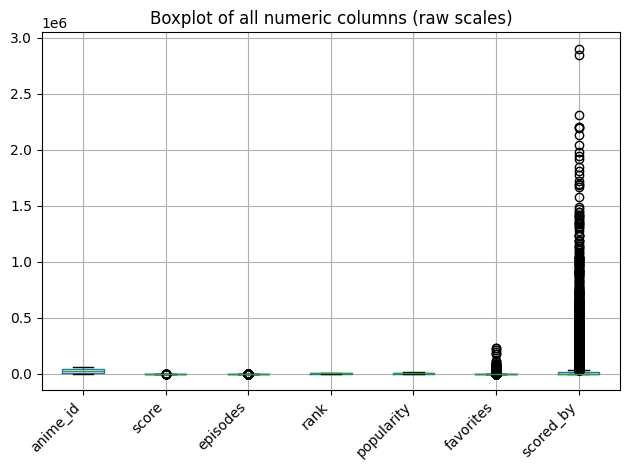

In [12]:
anime.boxplot()
plt.title('Boxplot of all numeric columns (raw scales)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [13]:
numeric_cols = anime.select_dtypes(include=['int64', 'float64']).columns

outlier_counts = {}
for col in numeric_cols:
    Q1 = anime[col].quantile(0.25)
    Q3 = anime[col].quantile(0.75)
    IQR = Q3 - Q1
    is_outlier = (anime[col] < Q1 - 1.5 * IQR) | (anime[col] > Q3 + 1.5 * IQR)
    outlier_counts[col] = is_outlier.sum()

pd.Series(outlier_counts, name='outlier_count')

anime_id         0
score           40
episodes      1270
rank             0
popularity       0
favorites     2581
scored_by     2370
Name: outlier_count, dtype: int64

**Finding:** `favorites` (2,581 outliers) and `scored_by` (2,370 outliers) have the most
IQR-flagged outliers, which is expected — a small number of extremely popular titles receive far
more favorites and ratings than the typical anime, producing a long right tail. `episodes` also
has a large outlier count (1,270), consistent with most titles having a short, standard episode
count and a minority (long-running series) extending far beyond it.

## 6. Exploratory Data Analysis

### 6.1 Top 10 most-favorited anime

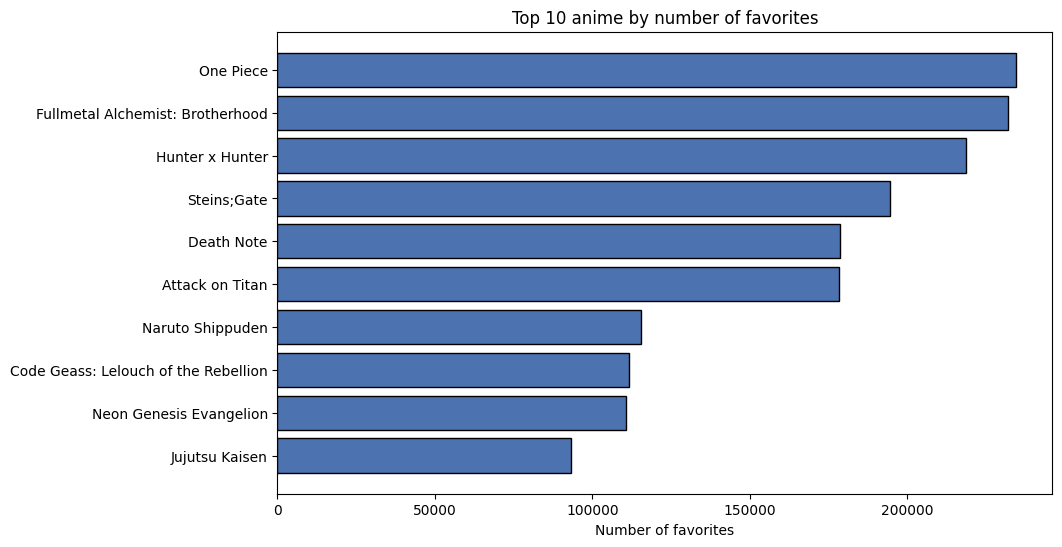

In [14]:
top10 = anime.nlargest(10, 'favorites')[['english_name', 'favorites']]

plt.figure(figsize=(10, 6))
plt.barh(top10['english_name'], top10['favorites'], color='#4C72B0', edgecolor='black')
plt.title("Top 10 anime by number of favorites")
plt.xlabel("Number of favorites")
plt.gca().invert_yaxis()
plt.show()

**Finding:** the ten most-favorited titles — led by *One Piece* (234K favorites),
*Fullmetal Alchemist: Brotherhood* (232K), and *Hunter x Hunter* (218K) — are all long-running
**TV series**, not movies or OVAs, and their favorite counts span roughly 93K to 234K. This
suggests that sustained audience attachment (favorites) in this dataset is driven more by shows
that stay in the cultural conversation over many episodes/years than by shorter-format content.


### 6.2 Average score by anime type

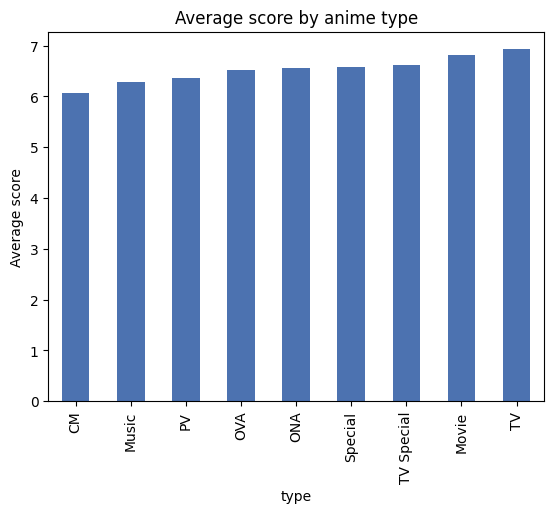

In [15]:
avg_score_type = anime.groupby('type')['score'].mean().sort_values(ascending=True)
avg_score_type.plot(kind='bar', title='Average score by anime type', color='#4C72B0')
plt.ylabel("Average score")
plt.show()

**Finding:** in this dataset, **TV** series have the highest average score (≈6.93),
followed closely by **Movie** (≈6.82); short-form types such as **CM** (≈6.07), **Music**
(≈6.29), and **PV** (≈6.37) score noticeably lower. The gap between the highest and lowest
category is close to 0.9 points.

> **Correction to the original analysis:** the notebook's original comment stated that Movie
> scored highest, followed by OVA and ONA, with TV Series "notably lower." Recomputing the
> grouped means from the actual data shows the opposite ordering at the top — **TV**, not Movie,
> has the highest average score, and OVA/ONA are in the *lower* half of the ranking, not the
> upper half. The commentary above reflects what the data actually shows.


### 6.3 Number of anime released per year

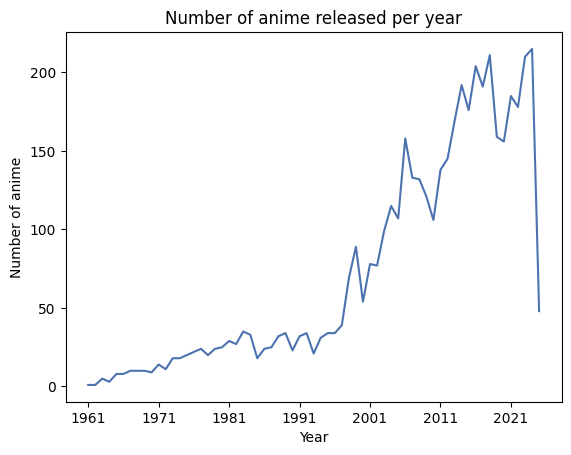

In [16]:
anime['year'] = anime['premiered'].str.extract(r'(\d{4})')
year_count = anime['year'].value_counts().sort_index()
year_count.plot(kind='line', title='Number of anime released per year', color='#4C72B0')
plt.xlabel('Year')
plt.ylabel("Number of anime")
plt.show()

**Finding:** among the ~4,700 titles with a known premiere year (recall: `premiered` is
missing for ~69% of the catalogue), output grew steadily from the 1960s through the 1990s, then
accelerated sharply from the early 2000s, peaking around 2016–2024 with several years above 190
titles (2018 and 2024 both exceed 210). The apparent drop after 2024 reflects the dataset's
collection cutoff (2025 is a partial year with only 52 titles recorded) rather than an actual
decline in industry output.

**Caveat:** because roughly two-thirds of titles have no `premiered` value, this trend should be
read as directional evidence from the subset of titles with known air dates, not a complete
picture of total industry output by year.


### 6.4 Average score by genre (top 10)

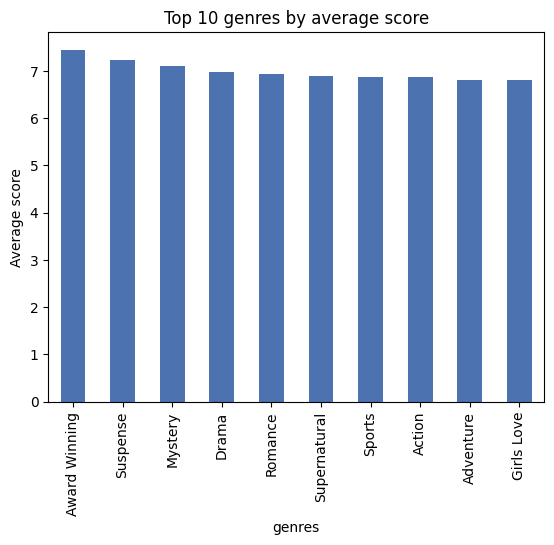

In [17]:
anime_genres = anime.dropna(subset=['genres']).copy()
anime_genres['genres'] = anime_genres['genres'].str.split(',')
anime_genres = anime_genres.explode('genres')
anime_genres['genres'] = anime_genres['genres'].str.strip().str.title()
genres_score = (anime_genres.groupby('genres')['score'].mean().sort_values(ascending=False).head(10))

genres_score.plot(kind='bar', title='Top 10 genres by average score', color='#4C72B0')
plt.ylabel("Average score")
plt.show()

**Finding:** the ten highest-scoring genres are *Award Winning*, *Suspense*, *Mystery*,
*Drama*, *Romance*, *Supernatural*, *Sports*, *Action*, *Adventure*, and *Girls Love*, with
average scores ranging from about 6.8 to 7.45. *Award Winning* stands out at the top (≈7.45), but
it is also one of the smallest genre groups in this list (209 titles), so its average is more
sensitive to a handful of highly-rated entries than genres like *Action* (4,135 titles) or
*Adventure* (2,808 titles). The gap across the rest of the top 10 is under one point, indicating
that once a genre is critically well-regarded, the differences between "top-tier" genres are
fairly small.


## 7. Key Findings

- Nearly 69% of titles are missing a `premiered` date, and other identifying fields
  (`english_name`, `rank`, `producers`) also have substantial gaps — any year-based or
  ranking-based analysis should be read with that in mind.
- The most-favorited anime are long-running TV series (led by *One Piece*, *Fullmetal Alchemist:
  Brotherhood*, and *Hunter x Hunter*), not movies or short-form content.
- **TV** and **Movie** types have the highest average scores (~6.8–6.9); short-form types (CM,
  Music, PV) score noticeably lower. This corrects an inaccurate claim in the original analysis
  that Movie scored highest.
- Recorded anime output grew steadily until the early 2000s and then accelerated, peaking in the
  2016–2024 window — though this is based on the ~31% of titles with a known premiere year.
- *Award Winning*, *Suspense*, and *Mystery* are the highest-scoring genres, but the small sample
  size behind *Award Winning* (209 titles) warrants some caution in over-interpreting its top
  ranking.


## 8. Conclusion and Recommendations

The catalogue's most-favorited and highest-scoring content skews toward long-format TV series and
character/plot-driven genres (Award Winning, Suspense, Mystery, Drama), while short-form content
(commercials, music videos, promotional videos) consistently scores lower — an intuitive result
given these formats are not designed to be rated as standalone narrative works. For a
content-strategy use case, this would point toward TV-series investment for building the kind of
long-term audience favoritism seen in the top-10 favorites list, while treating short-form
content's lower average scores as an artifact of format rather than a quality problem to fix.
